<a href="https://colab.research.google.com/github/BioML-UGent/Advanced-AI-for-Bioinformatics/blob/main/08_conformal_prediction/PC_lab_conformal_prediction_solved.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PC lab: Conformal prediction

A classifier usually returns one label, and a regressor one number. **Conformal prediction**, in contrast, returns a set of plausible labels or an interval of plausible values. In **part 1**, we return to the splice-site problem of PC lab 3. In **part 2**, we predict the error of a proposed protein structure.

**Learning goals**
- Calibrate prediction sets and intervals with a held-out (calibration) dataset
- Compare coverage with efficiency (set size or interval width)
- Distinguish marginal coverage from coverage within groups

Data loading, models and plotting are provided. The exercises focus on conformal prediction.

## 0 Setup


In [1]:
import io
import urllib.request
import zipfile

import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression, Ridge, QuantileRegressor
from sklearn.preprocessing import SplineTransformer

alpha = 0.1  # target miscoverage: 10%, so target coverage is 90%, How does changing this affect set size?


def read_zip(url, filename):
    content = urllib.request.urlopen(url, timeout=30).read()
    with zipfile.ZipFile(io.BytesIO(content)) as archive:
        return archive.read(filename)

# Part 1: Classification

## 1 From one label to a set

Instead of returning only "donor", we might return `{donor, neither}`. For a chosen error level $\alpha$, the goal is

$$\Pr\{Y_{\mathrm{new}} \in C(X_{\mathrm{new}})\} \geq 1-\alpha.$$

This is a **finite-sample, distribution-free** guarantee under **exchangeability**: permuting the examples does not change their joint distribution. Independent samples from the same distribution satisfy this condition.

We use **split conformal prediction**:
1. **Training set:** fit the model.
2. **Calibration set:** measure its errors and choose a threshold.
3. **Test set:** evaluate coverage and set size.

A better model can give smaller sets; conformal calibration itself does not improve its classification accuracy.

### The calibration threshold

A **nonconformity score** $s(x,y)$ is larger when a candidate label looks less plausible. On $n$ calibration examples, compute scores for the **true** labels. Set

$$k = \lceil(n+1)(1-\alpha)\rceil, \qquad \hat q = s_{(k)},$$

where $s_{(k)}$ is the $k$-th smallest calibration score. Include a candidate label when $s(x,y)\leq\hat q$.

<div class="alert alert-success">

<b>EXERCISE 1: the conformal quantile</b>

a) Complete `conformal_quantile`. Use `np.ceil` and `np.sort`; remember that Python indices start at 0. We will reuse this function throughout the lab.

</div>

In [ ]:
def conformal_quantile(scores, alpha):
    n = len(scores)
    k = int(np.ceil((n + 1) * (1 - alpha)))
    if k > n:
        return np.inf
    return np.sort(scores)[k - 1]

toy_scores = np.arange(1, 10) / 10
print(conformal_quantile(toy_scores, 0.1))   # 0.9

0.9


### The splice-site classifier

We reuse the [UCI splice-junction dataset](https://archive.ics.uci.edu/dataset/69/molecular-biology-splice-junction-gene-sequences) from PC lab 3: 3190 DNA sequences of 60 bases, labeled **donor**, **acceptor** or **neither**. We supply a simple logistic regression baseline using the **four bases around the center**, one-hot encoded. These contain the GT and AG motifs from PC lab 3. A CNN could be wrapped in the same conformal procedure.


In [3]:
url = "https://archive.ics.uci.edu/static/public/69/molecular+biology+splice+junction+gene+sequences.zip"
lines = read_zip(url, "splice.data").decode().strip().splitlines()
sequences = [line.split(",")[2].strip() for line in lines]
class_names = np.array(["donor", "acceptor", "neither"])
class_index = {"EI": 0, "IE": 1, "N": 2}
y = np.array([class_index[line.split(",")[0].strip()] for line in lines])

X = np.zeros((len(sequences), 4, 4))
for i, sequence in enumerate(sequences):
    for j, base in enumerate(sequence[28:32]):
        if base in "ACGT":
            X[i, j, "ACGT".index(base)] = 1
        else:
            X[i, j] = 0.25  # ambiguous base, as in PC lab 3
X = X.reshape(len(sequences), -1)

rng = np.random.default_rng(0)
train_idx, cal_idx, test_idx = np.split(rng.permutation(len(y)), [1800, 2500])
X_train, X_cal, X_test = X[train_idx], X[cal_idx], X[test_idx]
y_train, y_cal, y_test = y[train_idx], y[cal_idx], y[test_idx]

classifier = LogisticRegression(max_iter=1000)
classifier.fit(X_train, y_train)
p_cal = classifier.predict_proba(X_cal)    # rows: examples; columns: classes 0, 1, 2
p_test = classifier.predict_proba(X_test)
print("train / calibration / test:", len(y_train), len(y_cal), len(y_test))
print(f"single-label test accuracy: {(p_test.argmax(axis=1) == y_test).mean():.3f}")


train / calibration / test: 1800 700 690
single-label test accuracy: 0.906


## 2 LAC: thresholding class probabilities

The **least ambiguous classifier** (LAC) uses $s(x,y)=1-\hat p(y\mid x)$. Calibrate using the probability assigned to each true calibration label. Then include **every** test label with $1-\hat p(y\mid x)\leq\hat q$.

**Coverage** is the fraction of examples whose true label is in the set. **Efficiency** is measured by the average number of labels. Returning all three labels would cover everything, but tells us little.

In [8]:
def report_sets(name, sets, labels):
    coverage = sets[np.arange(len(labels)), labels].mean()
    size = sets.sum(axis=1).mean()
    print(f"{name:18s} coverage {coverage:.3f}, mean size {size:.2f}")


from collections import Counter

def show_sets(name, sets, labels):
    sizes = sets.sum(axis=1).astype(int)
    counts = Counter(sizes)
    total = len(sizes)

    print(name, "prediction set size distribution:")
    for size in sorted(counts):
        count = counts[size]
        print(f"size {size}: {count} ({count / total:.1%})")


<div class="alert alert-success">

<b>EXERCISE 2: LAC prediction sets</b>

a) Compute the calibration scores, the threshold `q_lac`, and a boolean matrix `sets_lac` with the same shape as `p_test`. A `True` means that the class is included. Hint: `p_cal[np.arange(len(y_cal)), y_cal]` selects the true-label probability in every row.

b) Run the summary and inspect the set size distribution. What would happen to their size if we asked for higher coverage?

</div>

In [9]:
scores_lac = 1 - p_cal[np.arange(len(y_cal)), y_cal]
q_lac = conformal_quantile(scores_lac, alpha)
sets_lac = (1 - p_test) <= q_lac

report_sets("LAC", sets_lac, y_test)
show_sets("LAC", sets_lac, y_test)

LAC                coverage 0.932, mean size 1.08
LAC prediction set size distribution:
size 1: 638 (92.5%)
size 2: 52 (7.5%)


**Answer:**

Higher target coverage means a smaller alpha and a higher score threshold. More labels can enter, so sets cannot shrink when the model and calibration scores are fixed. The sets can be empty or contain several labels; their mean size need not be at least one.


## 3 APS: using cumulative probability

**Adaptive prediction sets** (APS) sort the classes from most to least probable. The score of a candidate label is the cumulative probability **up to and including that label**. For probabilities `[0.2, 0.7, 0.1]`, the scores in the original class order are `[0.9, 0.7, 1.0]`.

We use the simple deterministic score, with ties ordered by class index. As before, calibrate the true-label scores and include labels whose score is at most $\hat q$.


<div class="alert alert-success">

<b>EXERCISE 3: APS prediction sets</b>

a) Complete `aps_scores`. For each row, sort class indices with `np.argsort`, compute `np.cumsum` in that order, and store the scores back in the original class order.

b) Calibrate APS and compare its coverage, mean size and set size distribution of LAC. Does APS necessarily give smaller sets?

</div>

In [10]:
def aps_scores(probabilities):
    scores = np.zeros_like(probabilities)
    for i in range(len(probabilities)):
        order = np.argsort(-probabilities[i], kind="stable")
        scores[i, order] = np.cumsum(probabilities[i, order])
    return scores


print(aps_scores(np.array([[0.2, 0.7, 0.1]])))  # [[0.9, 0.7, 1.0]]

scores_aps = aps_scores(p_cal)[np.arange(len(y_cal)), y_cal]
q_aps = conformal_quantile(scores_aps, alpha)
sets_aps = aps_scores(p_test) <= q_aps

report_sets("LAC", sets_lac, y_test)
report_sets("APS", sets_aps, y_test)
show_sets("APS", sets_aps, y_test)


[[0.9 0.7 1. ]]
LAC                coverage 0.932, mean size 1.08
APS                coverage 0.862, mean size 1.61
APS prediction set size distribution:
size 0: 91 (13.2%)
size 1: 89 (12.9%)
size 2: 510 (73.9%)


**Answer:**

No. In this run, LAC has mean size 1.08 and APS 1.61, with measured coverage 93.2% and 86.2%. Coverage on one fixed test split can fall below 90%; the guarantee averages over calibration and test draws. Their scores use different information. Neither method guarantees smaller sets on every dataset.


### Seeing the ranking and threshold

**Left:** sort the calibration scores and take rank `k` to find the threshold. **Right:** for test example 0, rank labels by predicted probability, then compare their scores with the threshold. Green labels enter the set; grey labels stay out. APS uses cumulative probability, while LAC uses one minus the label's probability. The same calibration rule applies to both.


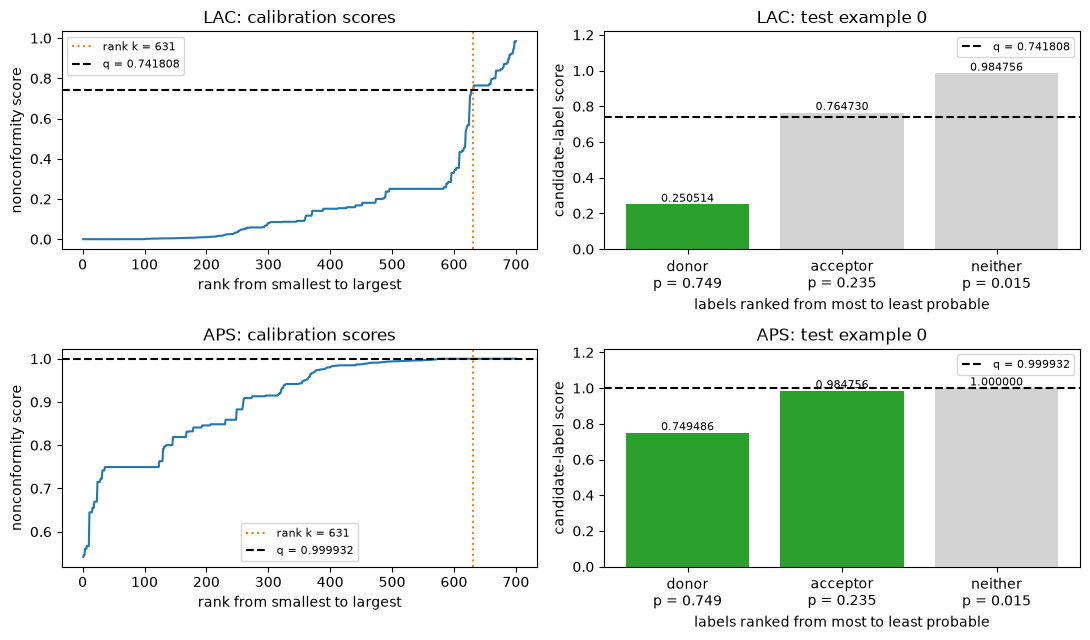

In [11]:
example = 0
methods = [("LAC", scores_lac, q_lac, 1 - p_test[example]),
           ("APS", scores_aps, q_aps, aps_scores(p_test[[example]])[0])]
fig, axes = plt.subplots(2, 2, figsize=(11, 6.5))
for row, (name, scores, threshold, candidate_scores) in enumerate(methods):
    ranks = np.arange(1, len(scores) + 1)
    k = int(np.ceil((len(scores) + 1) * (1 - alpha)))
    ax = axes[row, 0]
    ax.plot(ranks, np.sort(scores))
    ax.axvline(k, color="tab:orange", linestyle=":", label=f"rank k = {k}")
    ax.axhline(threshold, color="black", linestyle="--", label=f"q = {threshold:.6f}")
    ax.set_title(name + ": calibration scores")
    ax.set_xlabel("rank from smallest to largest")
    ax.set_ylabel("nonconformity score")
    ax.legend(fontsize=8)

    order = np.argsort(-p_test[example], kind="stable")
    values = candidate_scores[order]
    colors = ["tab:green" if value <= threshold else "lightgrey" for value in values]
    labels = [f"{class_names[j]}\np = {p_test[example, j]:.3f}" for j in order]
    ax = axes[row, 1]
    bars = ax.bar(labels, values, color=colors)
    ax.bar_label(bars, labels=[f"{value:.6f}" for value in values], fontsize=8)
    ax.axhline(threshold, color="black", linestyle="--", label=f"q = {threshold:.6f}")
    ax.set_title(name + ": test example 0")
    ax.set_xlabel("labels ranked from most to least probable")
    ax.set_ylabel("candidate-label score")
    ax.set_ylim(0, 1.22)
    ax.legend(fontsize=8, loc="upper right")
plt.tight_layout()
plt.show()


## 4 Does overall coverage hide a problem?

The guarantee is **marginal**: it averages over calibration data and a new example. It does not promise 90% coverage for every fixed calibration set, every input, or every subgroup.

Split the **DNA input space** by the four bases around the splice boundary: **AG|GT** (`sequence[28:32] == "AGGT"`) versus other central bases. AG before the boundary and GT after it match the acceptor and donor motifs, so these four bases alone can be ambiguous.

This is a fixed rule on the input sequence, using **no true label or predicted probability**. First, keep the same pooled LAC threshold for both groups and look at their measured coverage.


all test examples  coverage 0.932, mean size 1.08
other central bases test examples: 585
other central bases coverage 0.952, mean size 1.09
AG|GT at center test examples: 105
AG|GT at center    coverage 0.819, mean size 1.00


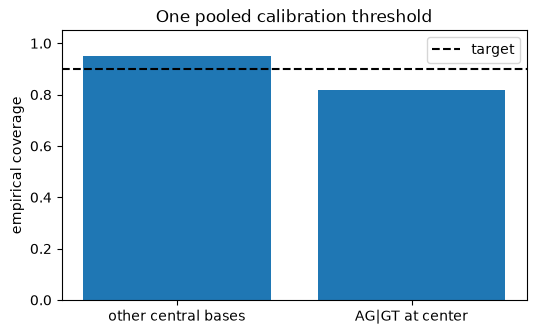

In [12]:
group_names = ["other central bases", "AG|GT at center"]
has_aggt = np.array([sequence[28:32] == "AGGT" for sequence in sequences])
groups_cal = has_aggt[cal_idx].astype(int)
groups_test = has_aggt[test_idx].astype(int)
covered_lac = sets_lac[np.arange(len(y_test)), y_test]
pooled_coverage = []

report_sets("all test examples", sets_lac, y_test)
for group in [0, 1]:
    mask = groups_test == group
    print(group_names[group], "test examples:", mask.sum())
    report_sets(group_names[group], sets_lac[mask], y_test[mask])
    pooled_coverage.append(covered_lac[mask].mean())

plt.figure(figsize=(6, 3.5))
plt.bar(group_names, pooled_coverage)
plt.axhline(1 - alpha, color="black", linestyle="--", label="target")
plt.ylim(0, 1.05)
plt.ylabel("empirical coverage")
plt.title("One pooled calibration threshold")
plt.legend()
plt.show()


<div class="alert alert-success">

<b>EXERCISE 4 (THINK): marginal vs conditional coverage</b>

a) Is the overall coverage near or above the target? Does that describe both groups well?

b) How can one group's poor coverage be hidden by the overall result? Look at the group sizes. Does this contradict the marginal guarantee?

</div>


**Answer:**

Overall coverage is 93.2%, but the 105 AG|GT examples have only 81.9% coverage. The 585 other examples have 95.2%. The larger, well-covered group dominates the average. This does not contradict a marginal guarantee: it does not give the same guarantee within every subgroup.


### Mondrian: calibrating within each group

Now give each group its **own** calibration threshold. This is **Mondrian conformal prediction**. Use only the calibration scores in group $g$ to compute $\hat q_g$, then apply that threshold to test inputs in the same group.

For a partition fixed before calibration, exchangeability within groups gives

$$\Pr\{Y_{\mathrm{new}}\in C(X_{\mathrm{new}})\mid G_{\mathrm{new}}=g\}\geq1-\alpha.$$

This is **group-conditional** coverage for these two groups, rather than coverage at every individual input. Each group has fewer calibration examples, so its threshold is less stable.


<div class="alert alert-success">

<b>EXERCISE 5: Mondrian calibration</b>

Complete the two lines below: calibrate LAC separately within each group, then form the corresponding test sets. Inspect the set size distribution and run the comparison plot. What changed in the coverage and sizes of the two groups?

</div>

other central bases calibration examples: 584
other central bases coverage 0.903, mean size 0.97
AG|GT at center calibration examples: 116
AG|GT at center    coverage 1.000, mean size 2.00
Mondrian prediction set size distribution:
size 0: 17 (2.5%)
size 1: 568 (82.3%)
size 2: 105 (15.2%)


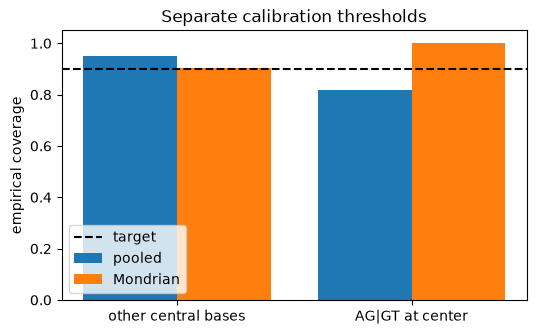

In [13]:
sets_mondrian = np.zeros_like(sets_lac)
for group in [0, 1]:
    cal_mask = groups_cal == group
    test_mask = groups_test == group
    q_group = conformal_quantile(scores_lac[cal_mask], alpha)
    sets_mondrian[test_mask] = (1 - p_test[test_mask]) <= q_group

for group in [0, 1]:
    mask = groups_test == group
    print(group_names[group], "calibration examples:", (groups_cal == group).sum())
    report_sets(group_names[group], sets_mondrian[mask], y_test[mask])

show_sets("Mondrian", sets_mondrian, y_test)
covered_mondrian = sets_mondrian[np.arange(len(y_test)), y_test]
mondrian_coverage = [covered_mondrian[groups_test == g].mean() for g in [0, 1]]
positions = np.arange(2)
plt.figure(figsize=(6, 3.5))
plt.bar(positions - 0.2, pooled_coverage, width=0.4, label="pooled")
plt.bar(positions + 0.2, mondrian_coverage, width=0.4, label="Mondrian")
plt.xticks(positions, group_names)
plt.axhline(1 - alpha, color="black", linestyle="--", label="target")
plt.ylim(0, 1.05)
plt.ylabel("empirical coverage")
plt.title("Separate calibration thresholds")
plt.legend()
plt.show()


**Answer:**

Coverage becomes 90.3% for other central bases and 100% for AG|GT. Discrete scores can make coverage conservative: the target is **at least** 90%, not exactly 90% or equal coverage between groups. There are 584 and 116 calibration examples, respectively.

---

# Part 2: Regression

## 5 Predicting protein-structure error

We use the [UCI protein tertiary-structure dataset](https://archive.ics.uci.edu/dataset/265/physicochemical+properties+of+protein+tertiary+structure), from CASP 5–9. Each row describes a proposed structure (**decoy**). The target is its **RMSD** from the reference structure, in Ångströms: smaller means closer to the reference.

We use one input: **F3, the nonpolar exposed-area fraction**. This lets us plot intervals directly against a biological feature. The supplied models use smooth spline features. You do not need to implement or tune them.

We randomly select 6000 rows to keep the lab fast: 4000 for training, 1000 for calibration and 1000 for testing. These are decoy rows, not necessarily independent protein targets. This random row split does not establish coverage on previously unseen protein families.


In [14]:
url = "https://archive.ics.uci.edu/static/public/265/physicochemical+properties+of+protein+tertiary+structure.zip"
protein_data = np.loadtxt(io.BytesIO(read_zip(url, "CASP.csv")), delimiter=",", skiprows=1)
rng = np.random.default_rng(0)
protein_data = protein_data[rng.permutation(len(protein_data))[:6000]]
X_train_reg, X_cal_reg, X_test_reg = np.split(protein_data[:, 3:4], [4000, 5000])  # F3
y_train_reg, y_cal_reg, y_test_reg = np.split(protein_data[:, 0], [4000, 5000])

# Provided smooth models: fit only on the training set
basis = SplineTransformer(n_knots=5, degree=3, extrapolation="linear")
B_train = basis.fit_transform(X_train_reg)
B_cal, B_test = basis.transform(X_cal_reg), basis.transform(X_test_reg)

point_model = Ridge(alpha=1).fit(B_train, y_train_reg)
training_errors = np.abs(y_train_reg - point_model.predict(B_train))
scale_model = Ridge(alpha=1).fit(B_train, np.log(training_errors + 0.1))

lower_model = QuantileRegressor(quantile=alpha / 2, alpha=0.001, solver="highs")
upper_model = QuantileRegressor(quantile=1 - alpha / 2, alpha=0.001, solver="highs")
lower_model.fit(B_train, y_train_reg)
upper_model.fit(B_train, y_train_reg)

pred_cal = point_model.predict(B_cal)
pred_test = point_model.predict(B_test)
print(f"point prediction test MAE: {np.abs(y_test_reg - pred_test).mean():.3f} Å")


point prediction test MAE: 4.882 Å


## 6 Absolute residuals: constant-width intervals

Start with $s(x,y)=|y-\hat\mu(x)|$, the absolute prediction error. Calibrate its threshold using the **calibration** residuals. The interval is

$$C(x)=[\hat\mu(x)-\hat q,\;\hat\mu(x)+\hat q].$$

Its width is $2\hat q$ for every input. Coverage now means that the observed RMSD falls between the endpoints; efficiency is the average interval width.


In [15]:
def report_interval(name, interval, values):
    lower, upper = interval
    coverage = ((lower <= values) & (values <= upper)).mean()
    width = np.maximum(upper - lower, 0).mean()
    print(f"{name:18s} coverage {coverage:.3f}, mean width {width:.2f} Å")

<div class="alert alert-success">

<b>EXERCISE 6: residual intervals</b>

Compute the absolute calibration residuals, calibrate `q_residual`, and store the lower and upper test endpoints in `intervals["Residual"]`. Reuse `conformal_quantile` from Exercise 1.

</div>


In [16]:
intervals = {}
scores_residual = np.abs(y_cal_reg - pred_cal)
q_residual = conformal_quantile(scores_residual, alpha)
intervals["Residual"] = (pred_test - q_residual, pred_test + q_residual)

report_interval("Residual", intervals["Residual"], y_test_reg)

Residual           coverage 0.895, mean width 18.43 Å


## 7 Normalized residuals: adapting the width

Some structures may be harder to predict. A positive scale model $\hat\sigma(x)$ estimates their typical absolute error. Normalize the score:

$$s(x,y)=\frac{|y-\hat\mu(x)|}{\hat\sigma(x)},\qquad C(x)=[\hat\mu(x)-\hat q\hat\sigma(x),\;\hat\mu(x)+\hat q\hat\sigma(x)].$$

The intervals remain symmetric around the point prediction, but their width varies. The supplied scale model predicts log error from training residuals; exponentiating gives a positive scale. Its accuracy affects efficiency; conformal validity does not require it to be a correct conditional standard deviation.


In [17]:
scale_cal = np.exp(scale_model.predict(B_cal))
scale_test = np.exp(scale_model.predict(B_test))


<div class="alert alert-success">

<b>EXERCISE 7: normalized intervals</b>

Divide the calibration residuals by `scale_cal` before calibrating. Then multiply the threshold by `scale_test` to get each test interval's half-width. Store the result in `intervals["Normalized"]`.

</div>


In [18]:
scores_normalized = np.abs(y_cal_reg - pred_cal) / scale_cal
q_normalized = conformal_quantile(scores_normalized, alpha)
half_width = q_normalized * scale_test
intervals["Normalized"] = (pred_test - half_width, pred_test + half_width)

report_interval("Normalized", intervals["Normalized"], y_test_reg)


Normalized         coverage 0.898, mean width 18.50 Å


## 8 Conformalized quantile regression (CQR)

Quantile models estimate a lower and upper bound directly, here the 5th and 95th percentiles. Their learned bounds alone need not give 90% coverage. **CQR** calibrates the score

$$s(x,y)=\max\{\hat\ell(x)-y,\;y-\hat u(x)\},$$

and returns $[\hat\ell(x)-\hat q,\;\hat u(x)+\hat q]$. The width and center can vary with the input; the interval need not be symmetric around our point model. Scores, and even $\hat q$, can be negative: calibration can shrink an overly wide base interval.

The helper below orders the two model outputs consistently, including if they cross.


In [19]:
def predict_bounds(X):
    B = basis.transform(X)
    lower = lower_model.predict(B)
    upper = upper_model.predict(B)
    return np.minimum(lower, upper), np.maximum(lower, upper)


lower_cal, upper_cal = predict_bounds(X_cal_reg)
lower_test, upper_test = predict_bounds(X_test_reg)
report_interval("raw quantiles", (lower_test, upper_test), y_test_reg)


raw quantiles      coverage 0.904, mean width 16.52 Å


<div class="alert alert-success">

<b>EXERCISE 8: CQR intervals</b>

Implement the score with `np.maximum`, calibrate its threshold, and adjust the two test bounds. Store the result in `intervals["CQR"]`. Do not replace negative scores by zero.

</div>


In [20]:
scores_cqr = np.maximum(lower_cal - y_cal_reg, y_cal_reg - upper_cal)
q_cqr = conformal_quantile(scores_cqr, alpha)
intervals["CQR"] = (lower_test - q_cqr, upper_test + q_cqr)

for name, interval in intervals.items():
    report_interval(name, interval, y_test_reg)


Residual           coverage 0.895, mean width 18.43 Å
Normalized         coverage 0.898, mean width 18.50 Å
CQR                coverage 0.914, mean width 16.73 Å


## 9 Comparing interval shapes

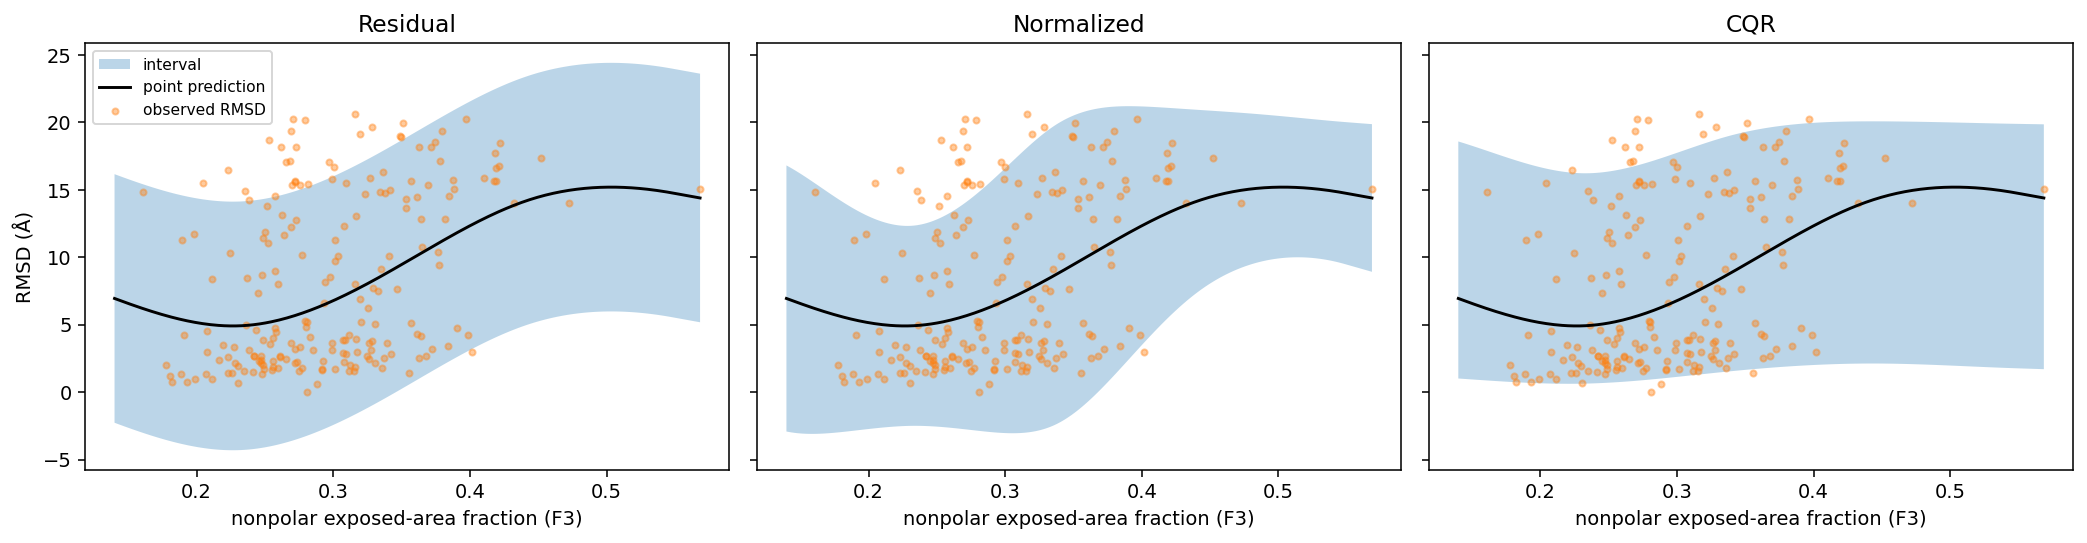

In [17]:
x_grid = np.linspace(X_test_reg.min(), X_test_reg.max(), 300)[:, None]
B_grid = basis.transform(x_grid)
pred_grid = point_model.predict(B_grid)
scale_grid = np.exp(scale_model.predict(B_grid))
lower_grid, upper_grid = predict_bounds(x_grid)
plot_intervals = {
    "Residual": (pred_grid - q_residual, pred_grid + q_residual),
    "Normalized": (pred_grid - q_normalized * scale_grid, pred_grid + q_normalized * scale_grid),
    "CQR": (lower_grid - q_cqr, upper_grid + q_cqr),
}

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, (name, (lower, upper)) in zip(axes, plot_intervals.items()):
    ax.fill_between(x_grid[:, 0], lower, upper, alpha=0.3, label="interval")
    ax.plot(x_grid[:, 0], pred_grid, color="black", label="point prediction")
    ax.scatter(X_test_reg[::5, 0], y_test_reg[::5], s=10, alpha=0.4,
               color="tab:orange", label="observed RMSD")
    ax.set_title(name)
    ax.set_xlabel("nonpolar exposed-area fraction (F3)")
axes[0].set_ylabel("RMSD (Å)")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()


<div class="alert alert-success">

<b>EXERCISE 9 (THINK): coverage, width and assumptions</b>

a) Which method has constant width? Which adapts the width, and which can also change the interval's center relative to the point model?

b) Compare the measured coverage and mean widths. Is CQR always the narrowest? Does coverage below 90% on one test split contradict the guarantee?

c) Do adaptive intervals guarantee coverage at every input? Would you expect the same guarantee when testing on a new protein family, or when related structures make the examples non-exchangeable?

</div>


**Answer:**

a) Residual intervals have constant width. Normalized intervals change width but remain centered on the point model. CQR learns two bounds, so its width and center can both change relative to that model.

b) Here the mean widths are 18.43 Å, 18.50 Å and 16.73 Å, with measured coverage 89.5%, 89.8% and 91.4%. CQR is narrowest in this example; this is not guaranteed for every problem. Compare efficiency alongside coverage. The guarantee averages over random calibration data and a new example; a single finite test split can fall below 90%.

c) All three guarantees are marginal, including for normalized intervals and CQR. Adapting the shape does not establish pointwise conditional coverage. A new family or dependence between related examples can break exchangeability, so random-row results do not establish coverage in that setting.
